# BHARATH BUILDS — 21 DAYS TO ML ENGINEER

## DAY 9 — SUPPORT VECTOR MACHINE (SVM)

**Channel:** Bharath Builds  
**Topic:** Support Vector Machine — Maximum-Margin Classification  
**Practical Dataset:** Breast Cancer Wisconsin Dataset  
**Technology:** Python, Google Colab, NumPy, Pandas, Matplotlib, Scikit-learn

### OBJECTIVES

1. Understand maximum-margin classification and decision boundaries.
2. Understand hyperplanes, margins, and support vectors.
3. Understand soft margin and the role of the C parameter.
4. Understand kernels and compare Linear SVM with RBF SVM.
5. Understand the importance of feature scaling and the gamma parameter.
6. Train, evaluate, and compare SVM models using Python.
7. Inspect misclassified samples and interpret model performance.

### TOPICS COVERED — THEORY

1. What is Support Vector Machine (SVM)?
2. Hyperplane and Margin
3. Support Vectors
4. Hard Margin vs Soft Margin
5. C Parameter and Regularization
6. Kernel Concept
7. Linear Kernel vs RBF Kernel
8. Gamma Parameter
9. Why Feature Scaling Matters
10. Advantages and Limitations of SVM
11. Computational Cost and Overfitting
12. SVM Interview Questions

### TOPICS COVERED — PRACTICAL

1. Import Required Libraries
2. Load the Breast Cancer Dataset
3. Separate Features and Target
4. Train-Test Split with Stratification
5. Feature Scaling using StandardScaler
6. Build an SVM Pipeline
7. Train Linear SVM
8. Train RBF SVM
9. Compare Different C Values
10. Tune C and Gamma using Cross-Validation
11. Evaluate Accuracy, Precision, Recall, and F1-Score
12. Visualize Confusion Matrices
13. Inspect Misclassified Samples
14. Compare Model Performance
15. Document Observations and Conclusions

### SVM MODELING PIPELINE

Dataset  
→ Feature and Target Separation  
→ Stratified Train-Test Split  
→ StandardScaler  
→ SVM Model  
→ Hyperparameter Tuning  
→ Model Prediction  
→ Performance Evaluation  
→ Confusion Matrix  
→ Error Analysis  
→ Final Conclusion

### KEY LEARNING PRINCIPLE

**EXPLAIN → IMPLEMENT → INTERPRET → DOCUMENT → COMMIT**

The goal is not just to train the model.

The goal is to understand what the model learns, how hyperparameters affect its decision boundary, where it makes mistakes, and how well it generalizes to unseen data.

### DAY 9 DELIVERABLE

A complete SVM comparison practical containing Linear and RBF models, hyperparameter tuning, evaluation metrics, confusion matrices, error analysis, and interview-ready conclusions.

**Bharath Builds | Learn by Building | Build Your ML Portfolio**

step 1: import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    make_scorer
)

RANDOM_STATE = 42

step 2 : load the dataset

In [2]:
dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass mapping:")
print("0 = Malignant")
print("1 = Benign")

print("\nClass distribution:")
print(
    y.map({0: "Malignant", 1: "Benign"})
     .value_counts()
)

Feature matrix shape: (569, 30)
Target shape: (569,)

Class mapping:
0 = Malignant
1 = Benign

Class distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64


In [3]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [4]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


step 3: split the datset

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


step4: feature scaling and Pipeline

In [8]:
# linear svm

linear_model=Pipeline([
    ('scaler', StandardScaler()),
    ('linear_svm', SVC(kernel='linear',C=1.0))
])

rbf_model=Pipeline([
    ('scaler', StandardScaler()),
    ('rbf_svm', SVC(kernel='rbf',C=1.0))
])

print("linear and rbf pipelines build successfully")

linear and rbf pipelines build successfully


step5: Train Linear SVM and RBF SVM

In [9]:
linear_model.fit(X_train, y_train)
rbf_model.fit(X_train, y_train)

print("linear and rbf models trained successfully")

linear and rbf models trained successfully


step6: Evaluate models performance

In [13]:
def evaluate_model(model, X_eval, y_eval, model_name):
    predictions = model.predict(X_eval)

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision (Malignant)": precision_score(
            y_eval, predictions, pos_label=0, zero_division=0
        ),
        "Recall (Malignant)": recall_score(
            y_eval, predictions, pos_label=0, zero_division=0
        ),
        "F1 (Malignant)": f1_score(
            y_eval, predictions, pos_label=0, zero_division=0
        ),
        "F1 (Benign)": f1_score(
            y_eval, predictions, pos_label=1, zero_division=0
        )
    }

results = pd.DataFrame([
    evaluate_model(
        linear_model, X_test, y_test, "Linear SVM"
    ),
    evaluate_model(
        rbf_model, X_test, y_test, "RBF SVM"
    )
])

results.round(4)

,Model,Accuracy,Precision (Malignant),Recall (Malignant),F1 (Malignant),F1 (Benign)
0,Linear SVM,0.9737,0.9535,0.9762,0.9647,0.9790
1,RBF SVM,0.9825,0.9762,0.9762,0.9762,0.9861


step7: confusion matrix and classification report



linear svm
              precision    recall  f1-score   support

   Malignant       0.95      0.98      0.96        42
      Benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



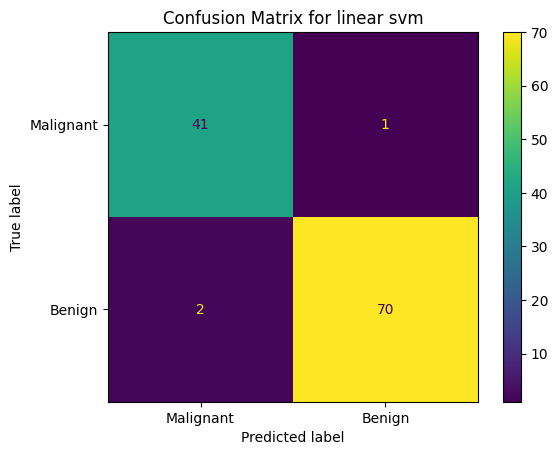


RBF svm
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



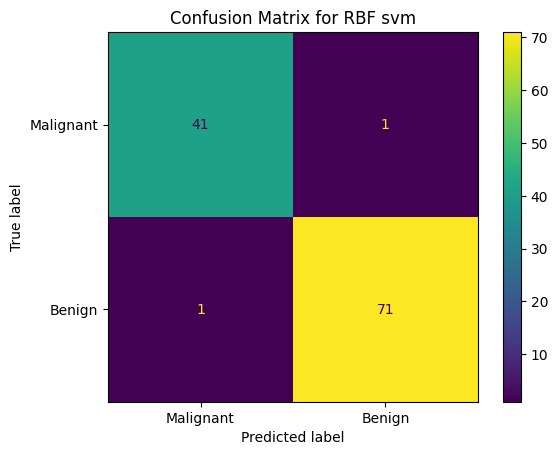

In [17]:
for name,model in[("linear svm",linear_model),("RBF svm",rbf_model)]:
    predictions=model.predict(X_test)

    cm=confusion_matrix(y_test,predictions,labels=[0,1])

    print(f"\n{name}")
    print(classification_report(y_test,predictions,labels=[0,1],target_names=["Malignant","Benign"]))

    disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Malignant","Benign"])
    disp.plot()
    plt.title(f"Confusion Matrix for {name}")
    plt.show()



Step 8 — Compare Different C Values

In [20]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

c_values = [0.1, 1, 10, 100]
c_results = []

for c_value in c_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", C=c_value))
    ])

    scores = []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]

        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        model.fit(X_fold_train, y_fold_train)
        predictions = model.predict(X_fold_val)

        score = f1_score(
            y_fold_val,
            predictions,
            pos_label=0,
            zero_division=0
        )

        scores.append(score)

    c_results.append({
        "C": c_value,
        "Mean CV Malignant F1": np.mean(scores),
        "Std CV Malignant F1": np.std(scores)
    })

c_results_df = pd.DataFrame(c_results)

c_results_df.round(4)

,C,Mean CV Malignant F1,Std CV Malignant F1
0,0.1,0.9667,0.0157
1,1.0,0.9524,0.0226
2,10.0,0.9528,0.0288
3,100.0,0.9244,0.0205


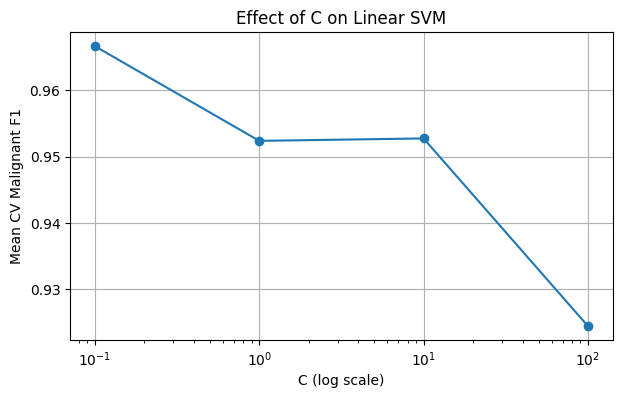

In [21]:
plt.figure(figsize=(7, 4))

plt.plot(
    c_results_df["C"],
    c_results_df["Mean CV Malignant F1"],
    marker="o"
)

plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Mean CV Malignant F1")
plt.title("Effect of C on Linear SVM")
plt.grid(True)
plt.show()

Step 9 — Compare RBF Kernel Settings

In [23]:
rbf_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1, 1]
}

malignant_f1_scorer = make_scorer(
    f1_score,
    pos_label=0,
    zero_division=0
)

grid_search = GridSearchCV(
    estimator=rbf_pipeline,
    param_grid=param_grid,
    scoring=malignant_f1_scorer,
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print(
    "Best mean CV malignant F1:",
    round(grid_search.best_score_, 4)
)

Best parameters: {'svm__C': 10, 'svm__gamma': 0.01}
Best mean CV malignant F1: 0.9668


step 10 : evaluate tuned RBF Model

In [24]:
best_rbf_model = grid_search.best_estimator_
best_rbf_model.fit(X_train, y_train)

rbf_predictions = best_rbf_model.predict(X_test)

tuned_rbf_results =evaluate_model(
    best_rbf_model,
    X_test,
    y_test,
    "Tuned RBF SVM"
)

tuned_rbf_results = pd.DataFrame(
    [tuned_rbf_results]).round(4)

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



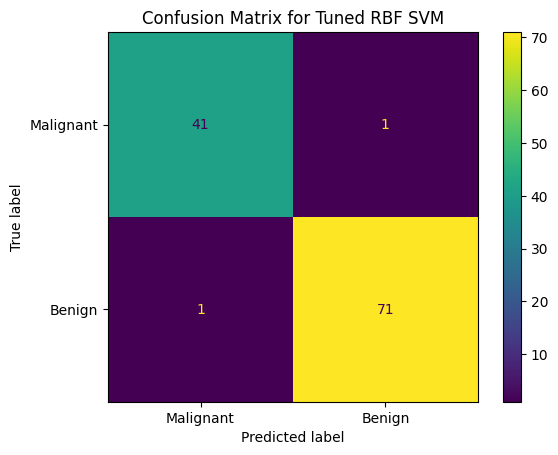

classification_report               precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [28]:
cm=confusion_matrix(y_test,rbf_predictions,labels=[0,1])

print(classification_report(y_test,rbf_predictions,labels=[0,1],target_names=["Malignant","Benign"]))

disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Malignant","Benign"])
disp.plot()
plt.title("Confusion Matrix for Tuned RBF SVM")
plt.show()

print("classification_report",classification_report(y_test,rbf_predictions,labels=[0,1],target_names=["Malignant","Benign"]))

step11: inspect mismatch samples classified one

In [31]:
error_mask = rbf_predictions != y_test.to_numpy()
error_positions = np.where(error_mask)[0]

errors = X_test.iloc[error_positions].copy()

errors["Actual Label"] = y_test.iloc[error_positions].to_numpy()
errors["Predicted Label"] = rbf_predictions[error_positions]

errors["Actual Class"] = errors["Actual Label"].map({
    0: "Malignant",
    1: "Benign"
})

errors["Predicted Class"] = errors["Predicted Label"].map({
    0: "Malignant",
    1: "Benign"
})

print("Number of misclassified samples:", len(errors))

display(
    errors[
        ["Actual Class", "Predicted Class"]
        + list(X.columns[:5])
    ].head(10)
)

Number of misclassified samples: 2


,Actual Class,Predicted Class,mean radius,mean texture,mean perimeter,mean area,mean smoothness
541,Benign,Malignant,14.47,24.99,95.81,656.4,0.08837
73,Malignant,Benign,13.80,15.79,90.43,584.1,0.10070


Step 12 — Final Model Comparison

In [32]:
final_comparison = pd.DataFrame([
    evaluate_model(
        linear_model, X_test, y_test, "Linear SVM (C=1)"
    ),
    evaluate_model(
        rbf_model, X_test, y_test, "RBF SVM (C=1)"
    ),
    evaluate_model(
        best_rbf_model, X_test, y_test, "Tuned RBF SVM"
    )
])

final_comparison.round(4)

,Model,Accuracy,Precision (Malignant),Recall (Malignant),F1 (Malignant),F1 (Benign)
0,Linear SVM (C=1),0.9737,0.9535,0.9762,0.9647,0.9790
1,RBF SVM (C=1),0.9825,0.9762,0.9762,0.9762,0.9861
2,Tuned RBF SVM,0.9825,0.9762,0.9762,0.9762,0.9861


### Interpretation of SVM Results

- **Linear SVM (C=1):** Achieved **97.37% accuracy**, with **96.47% F1-score for malignant cases**.
- **RBF SVM (C=1):** Improved accuracy to **98.25%** and malignant F1-score to **97.62%**.
- **Malignant Recall:** Both models achieved **97.62% recall**, meaning they correctly identified most malignant cases.
- **RBF Advantage:** RBF performed better overall, capturing nonlinear patterns in the dataset.
- **Tuned RBF SVM:** Results remained the same as the baseline RBF model, so tuning did not improve the reported metrics.
- **Benign Classification:** Tuned and baseline RBF achieved **98.61% benign F1-score**, compared with **97.90% for Linear SVM**.
- **Final Observation:** RBF SVM is the best choice among these results, with **98.25% accuracy** and strong performance on both classes.
- **Important:** Since this is a medical dataset, false negatives matter. Check the confusion matrix and validate results before making any real-world medical conclusions.